# Step 4 — how much of the AUROC comes from features that overlap with what PHQ-9 measures

None of these features is derived from PHQ-9 (so they are not leakage), but they ask about things the PHQ-9 items also cover.

| group | PHQ-9 overlap | features |
|---|---|---|
| sleep | item 3 (sleep) | SLQ050, sleep_hours |
| self_health | self-rated general health | HSD010, HUQ010, HUQ020 |
| function | item 10 (difficulty), also fatigue and concentration | PFQ049, PFQ051, PFQ054, PFQ057 (confusion/memory), PFQ090, pf_difficulty_count, pf_severe_count, pf_notdo_count, not_working_reason |

**Variants** (same people, folds and grids as step 1): `all` = all three groups removed, logreg and xgboost; `sleep` / `self_health` / `function` = one group removed, xgboost only (the two models tie in steps 1 and 3).

**Output:** `$NHANES_WORK/modeling/step4_overlap/<variant>/` (same files as step 1)

`RUN = True` retrains the variants in `VARIANTS_TO_RUN` (about 3 hours for all four); `QUICK = True` with it runs one outer fold with the smallest grids. `RUN = False` only shows the saved results.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step4_overlap/<variant>
QUICK = False  # with RUN: one outer fold, smallest grids
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step4_overlap"

GROUPS = {
    "sleep": ["SLQ050", "sleep_hours"],
    "self_health": ["HSD010", "HUQ010", "HUQ020"],
    "function": ["PFQ049", "PFQ051", "PFQ054", "PFQ057", "PFQ090", "pf_difficulty_count", "pf_severe_count",
                 "pf_notdo_count", "not_working_reason"],
}
VARIANTS = {**{g: (cols, ("xgboost",)) for g, cols in GROUPS.items()},
            "all": (sum(GROUPS.values(), []), ("logreg", "xgboost"))}
VARIANTS_TO_RUN = list(VARIANTS)

## Run

In [2]:
if RUN:
    from nhanes.loco import FEAT, run_loco
    data = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    for name in VARIANTS_TO_RUN:
        drop, models = VARIANTS[name]
        assert set(drop) <= set(data.columns), set(drop) - set(data.columns)
        print(f"== {name}: drop {len(drop)} features, {data.shape[1] - 8 - len(drop)} left; {models}", flush=True)
        run_loco(data.drop(columns=drop), dic, OUT / name, QUICK, models=models,
                 title=f"leave-one-cycle-out, outcome PHQ-9 >= 10; without PHQ-overlap group '{name}': {drop}")

## Results

In [3]:
full = pd.read_csv(RESULTS / "step1" / "metrics.csv")
rows = [full.assign(variant="full (step 1)")]
for name in VARIANTS:
    rows.append(pd.read_csv(OUT / name / "metrics.csv").assign(variant=f"without {name}"))
met = pd.concat(rows, ignore_index=True)
table = (met.groupby(["variant", "model"], sort=False)
         .agg(auroc=("auroc", "mean"), sd=("auroc", "std"), auprc=("auprc", "mean")).round(3))
table["vs full"] = (table.auroc - table.auroc.xs("full (step 1)").reindex(table.index.get_level_values("model")).to_numpy()).round(3)
display(table)

auroc     sd  auprc  vs full
variant             model                                
full (step 1)       logreg   0.874  0.011  0.481    0.000
                    xgboost  0.871  0.010  0.481    0.000
without sleep       xgboost  0.861  0.009  0.467   -0.010
without self_health xgboost  0.862  0.012  0.462   -0.009
without function    xgboost  0.865  0.014  0.447   -0.006
without all         logreg   0.835  0.017  0.398   -0.039
                    xgboost  0.833  0.016  0.395   -0.038

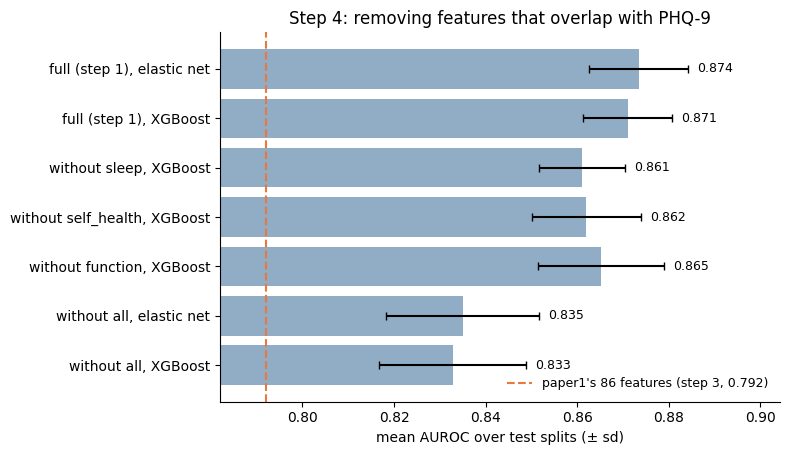

In [4]:
s = met.assign(label=met.variant + ", " + met.model.map({"logreg": "elastic net", "xgboost": "XGBoost"}))
summary = s.groupby("label", sort=False).auroc.agg(mean="mean", sd="std")
plots.mean_auroc_bars(summary, title="Step 4: removing features that overlap with PHQ-9",
                      ref=0.792, ref_label="paper1's 86 features (step 3, 0.792)")
plots.show()